
# Imam Abdulrahman Bin Faisal University
## ARTI 502 – Deep Learning
### Assignment 2: Training-Testing CNN with CIFAR Dataset using Pytorch

**Instructor:** Dr. Moatasem Alsmadi

**Group Number:** 4

**Group Members:**
1. Renad Salem Alqahtani – 2230004724
2. Jana Omar Alghamdi – 2230002367
3. Jood Yasser Alarfaj – 2230002692
4. Leen Mansour Alqahtani – 2230006599
5. Ghala Nassar Al-muriki – 2230006331
6. Wajd Mohammed Alqahtani – 2230005130


## Task 1: Getting the CIFAR Dataset

In [1]:
import torch
import torchvision
import torchvision.transforms as transforms
import os

DATA_PATH = './cifar_data'
os.makedirs(DATA_PATH, exist_ok=True)

transform = transforms.Compose([
    transforms.ToTensor()
])

trainset = torchvision.datasets.CIFAR10(
    root=DATA_PATH,
    train=True,
    download=True,
    transform=transform
)

testset = torchvision.datasets.CIFAR10(
    root=DATA_PATH,
    train=False,
    download=True,
    transform=transform
)

print("CIFAR-10 Dataset loaded successfully!")
print("Total training samples:", len(trainset))
print("Total testing samples:", len(testset))


100%|██████████| 170M/170M [00:26<00:00, 6.37MB/s]


CIFAR-10 Dataset loaded successfully!
Total training samples: 50000
Total testing samples: 10000


##Task 2: Defining the Network


**Network Architecture Definition**

In [2]:
import torch.nn as nn
import torch.nn.functional as F

class CNN(nn.Module):
    def __init__(self):
        super(CNN, self).__init__()
        # Conv block 1: in_channels=3 (RGB), out_channels=32, kernel_size=3, stride=1, padding=1
        self.conv1 = nn.Conv2d(in_channels=3, out_channels=32, kernel_size=3, stride=1, padding=1)
        # Conv block 2: in_channels=32, out_channels=64, kernel_size=3, stride=1, padding=1
        self.conv2 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, stride=1, padding=1)

        # Maxpooling layer: kernel_size=2, stride=2
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        # Fully connected layers (Classifier)
        # Input image: 32x32 -> After pool 1: 16x16 -> After pool 2: 8x8 -> 64 channels * 8 * 8
        self.fc1 = nn.Linear(64 * 8 * 8, 128)
        self.fc2 = nn.Linear(128, 10)  # 10 output classes for CIFAR-10

    def forward(self, x):
        # Feature extraction using convolution, activation, and maxpooling
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))

        # Flatten feature maps before feeding into the classifier
        x = x.view(x.size(0), -1)

        # Classification head
        x = F.relu(self.fc1(x))
        x = self.fc2(x)
        return x

# Instantiate the model
model = CNN()
print(model)

CNN(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=4096, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)


**Base Training & Testing Functions**

In [3]:

import torch
import torch.nn as nn
import torch.optim as optim

# Training function
def train(model, trainloader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in trainloader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / total
    epoch_accuracy = 100 * correct / total

    return epoch_loss, epoch_accuracy


# Testing function
def test(model, testloader, criterion, device):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in testloader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    test_loss = running_loss / total
    test_accuracy = 100 * correct / total

    return test_loss, test_accuracy


##Task 3: Loading Data

Part 1: Find the images tensor size

In [4]:
from torch.utils.data import DataLoader

# Load a batch of 8 images
trainloader = DataLoader(trainset, batch_size=8, shuffle=True)

# Get the images and labels
images, labels = next(iter(trainloader))

# Print their sizes
print("Images tensor size:", images.shape)
print("Labels tensor size:", labels.shape)


Images tensor size: torch.Size([8, 3, 32, 32])
Labels tensor size: torch.Size([8])


Part 2: Visualize images using Matplotlib

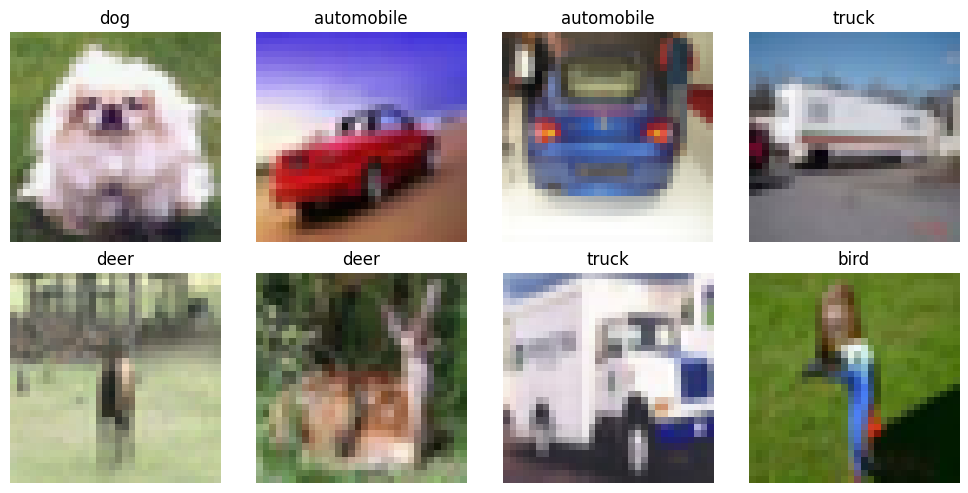

In [5]:
import matplotlib.pyplot as plt

# Display the images
fig, axes = plt.subplots(2, 4, figsize=(10, 5))

for i, ax in enumerate(axes.flat):
    image = images[i].permute(1, 2, 0)
    ax.imshow(image)
    ax.set_title(trainset.classes[labels[i].item()])
    ax.axis('off')

plt.tight_layout()
plt.show()


##Task 4: Dataset Augmentation

## Task 4: Dataset Augmentation

Data augmentation is applied to the CIFAR-10 training dataset
to introduce variations in the images and improve the CNN model's
ability to generalize.

The techniques include horizontal flipping, random cropping,
color jittering, rotation, Gaussian noise, and normalization.
Image format conversions are also demonstrated.

In [6]:
# Task 4: Dataset Augmentation

import torch
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader

# Custom Gaussian Noise Transformation
class AddGaussianNoise:
    def __init__(self, mean=0.0, std=0.05):
        self.mean = mean
        self.std = std

    def __call__(self, tensor):
        noise = torch.randn_like(tensor) * self.std + self.mean
        return torch.clamp(tensor + noise, 0.0, 1.0)

print("Gaussian Noise transformation defined successfully!")

Gaussian Noise transformation defined successfully!


In [7]:
# CIFAR-10 Normalization Parameters
CIFAR_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR_STD = (0.2470, 0.2435, 0.2616)

# Training Transformations
train_transform = transforms.Compose([

    transforms.RandomHorizontalFlip(p=0.5),

    transforms.RandomResizedCrop(
        size=32,
        scale=(0.8, 1.0)
    ),

    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2,
        hue=0.1
    ),

    transforms.RandomRotation(degrees=15),

    transforms.ToTensor(),

    AddGaussianNoise(mean=0.0, std=0.05),

    transforms.Normalize(
        mean=CIFAR_MEAN,
        std=CIFAR_STD
    )
])

# Testing Transformations
test_transform = transforms.Compose([

    transforms.ToTensor(),

    transforms.Normalize(
        mean=CIFAR_MEAN,
        std=CIFAR_STD
    )
])

print("Data Augmentation transformations defined successfully!")

Data Augmentation transformations defined successfully!


In [8]:
# Load CIFAR-10 Training Dataset
augmented_trainset = torchvision.datasets.CIFAR10(
    root=DATA_PATH,
    train=True,
    download=False,
    transform=train_transform
)

# Load CIFAR-10 Testing Dataset
augmented_testset = torchvision.datasets.CIFAR10(
    root=DATA_PATH,
    train=False,
    download=False,
    transform=test_transform
)

# Create DataLoaders
augmented_trainloader = DataLoader(
    augmented_trainset,
    batch_size=32,
    shuffle=True
)

augmented_testloader = DataLoader(
    augmented_testset,
    batch_size=32,
    shuffle=False
)

# Display Dataset Information
print("Augmented training samples:", len(augmented_trainset))
print("Testing samples:", len(augmented_testset))

# Check Tensor Shapes
train_images, train_labels = next(iter(augmented_trainloader))
test_images, test_labels = next(iter(augmented_testloader))

print("Training batch shape:", train_images.shape)
print("Testing batch shape:", test_images.shape)

Augmented training samples: 50000
Testing samples: 10000
Training batch shape: torch.Size([32, 3, 32, 32])
Testing batch shape: torch.Size([32, 3, 32, 32])


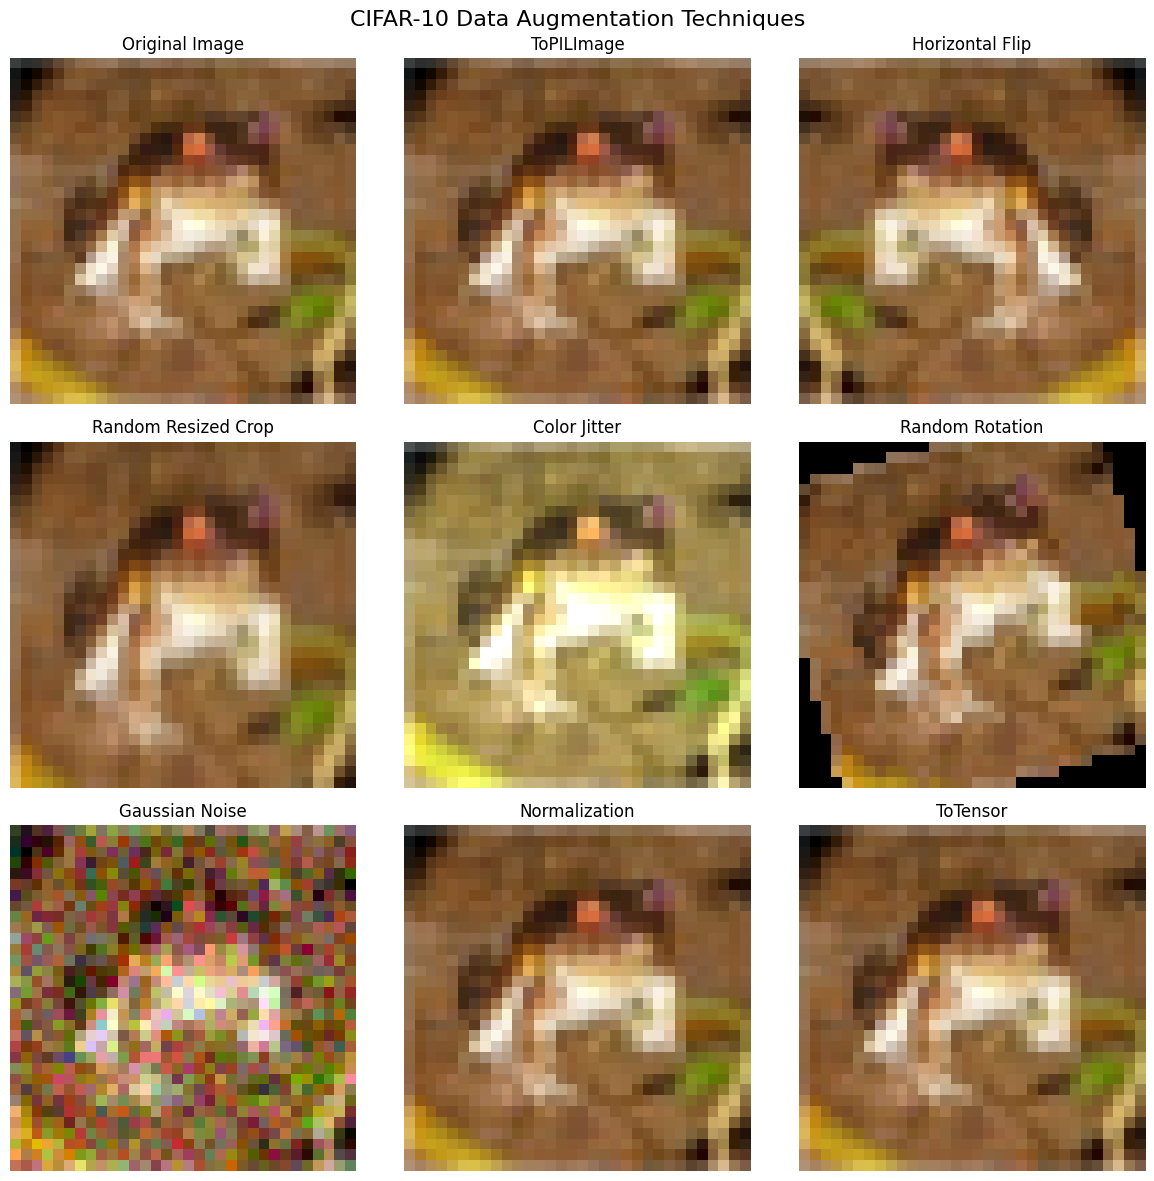

In [9]:
# Visualize Different Data Augmentation Techniques

# Get original CIFAR-10 image
original_tensor, label = trainset[0]

# Convert Tensor to PIL Image
pil_image = transforms.ToPILImage()(original_tensor)

# Define Individual Augmentation Techniques
augmentation_methods = {

    "Original Image":
        transforms.Lambda(lambda img: img),

    "ToPILImage":
        transforms.ToPILImage(),

    "Horizontal Flip":
        transforms.RandomHorizontalFlip(p=1.0),

    "Random Resized Crop":
        transforms.RandomResizedCrop(
            size=32,
            scale=(0.8, 1.0)
        ),

    "Color Jitter":
        transforms.ColorJitter(
            brightness=0.4,
            contrast=0.4,
            saturation=0.4,
            hue=0.1
        ),

    "Random Rotation":
        transforms.RandomRotation(degrees=(15, 15)),

    "Gaussian Noise":
        AddGaussianNoise(mean=0.0, std=0.1),

    "Normalization":
        transforms.Normalize(
            mean=CIFAR_MEAN,
            std=CIFAR_STD
        ),

    "ToTensor":
        transforms.ToTensor()
}

# Create Figure
fig, axes = plt.subplots(3, 3, figsize=(12, 12))

for ax, (name, transform_fn) in zip(
    axes.flat,
    augmentation_methods.items()
):

    if name == "ToPILImage":
        transformed = transform_fn(original_tensor)
        display_image = transformed

    elif name == "Gaussian Noise":
        transformed = transform_fn(original_tensor)
        display_image = transformed.permute(1, 2, 0)

    elif name == "Normalization":
        transformed = transform_fn(original_tensor)

        # Reverse normalization for correct visualization
        mean = torch.tensor(CIFAR_MEAN).view(3, 1, 1)
        std = torch.tensor(CIFAR_STD).view(3, 1, 1)

        display_image = (
            transformed * std + mean
        ).clamp(0, 1).permute(1, 2, 0)

    elif name == "ToTensor":
        transformed = transform_fn(pil_image)
        display_image = transformed.permute(1, 2, 0)

    else:
        transformed = transform_fn(pil_image)
        display_image = transformed

    ax.imshow(display_image)
    ax.set_title(name)
    ax.axis("off")

plt.suptitle(
    "CIFAR-10 Data Augmentation Techniques",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [10]:
# Verify Augmented Dataset

assert len(augmented_trainset) == 50000
assert len(augmented_testset) == 10000

assert train_images.shape == (32, 3, 32, 32)
assert test_images.shape == (32, 3, 32, 32)

assert torch.isfinite(train_images).all()
assert torch.isfinite(test_images).all()

# Verify PIL conversion
assert pil_image.size == (32, 32)

print("All augmentation checks passed successfully!")
print("Augmented dataset is ready for CNN training.")

All augmentation checks passed successfully!
Augmented dataset is ready for CNN training.


### Task 4: Dataset Augmentation

In this task, different data augmentation techniques were implemented on the CIFAR-10 dataset using PyTorch.

The techniques include RandomHorizontalFlip, RandomResizedCrop, ColorJitter, RandomRotation, Gaussian Noise, and Normalize. Additionally, ToTensor and ToPILImage were used for image format conversion.

These transformations introduce variations in the training images, which can help improve the CNN model's generalization and reduce overfitting.

Data augmentation was applied only to the training dataset. The testing dataset was converted to tensors and normalized using the same normalization parameters without applying random augmentations.

Matplotlib was used to visualize the original images and the effects of different augmentation techniques.

##Task 5: Training Function and Tuning hyperparameters